# Stage 9 — Bloom-Event Detection

Convert the continuous H+1 … H+7 `log10(CHL)` forecasts into operational event signals and score them with POD, FAR, CSI and F1.

## Definitions used in the three-year development run

1. **Median + 5% (`median5`)** — forecast or truth exceeds 1.05 times the per-pixel annual reference median. This is retained as an auxiliary above-median regime diagnostic; it is not treated as a rare event.
2. **Monthly percentile (`percentile`)** — forecast or truth exceeds the per-pixel calendar-month P90.
3. **Monthly standardized anomaly (`zscore`)** — truth exceeds 1.5 standard deviations above its per-pixel calendar-month mean.

The rare-event forecast cutoffs are calibrated only on 2022 predictions from models fitted only on 2021, then evaluated once on the untouched 2023 test year. Cumulative-sum bloom phenology is deferred to full-grid annual inference because it cannot be calculated validly from the sparse supervised sample.

## 9.0 — Config + load v2 models, sample, full CHL cube

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import xgboost as xgb

RAW_DIR = Path("data/raw")
PROC_DIR = Path("data/processed")
MODEL_DIR = Path("models")
FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_MANIFEST_PATH = PROC_DIR / "feature_manifest_v2.json"
SPLIT_MANIFEST_PATH = PROC_DIR / "split_manifest.json"
MODEL_MANIFEST_PATH = PROC_DIR / "xgb_v2_model_manifest.json"
SAMPLE_PATH = PROC_DIR / "supervised_sample_v2.parquet"

for path in (
    FEATURE_MANIFEST_PATH,
    SPLIT_MANIFEST_PATH,
    MODEL_MANIFEST_PATH,
    SAMPLE_PATH,
):
    if not path.exists():
        raise FileNotFoundError(path)

manifest = json.loads(FEATURE_MANIFEST_PATH.read_text())
split_protocol = json.loads(SPLIT_MANIFEST_PATH.read_text())
model_metadata = json.loads(MODEL_MANIFEST_PATH.read_text())

FEATURE_COLS = manifest["feature_cols"]
HORIZONS = manifest["horizons"]
BEST_ROUNDS = {
    int(h): int(rounds)
    for h, rounds in model_metadata["best_rounds"].items()
}

sample = (
    pd.read_parquet(SAMPLE_PATH)
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)
sample["time"] = pd.to_datetime(sample["time"])

if len(sample) != 360_000:
    raise RuntimeError(
        f"Expected 360,000 rows; found {len(sample):,}"
    )

missing_features = set(FEATURE_COLS) - set(sample.columns)
if missing_features:
    raise RuntimeError(
        f"Sample is missing features: {sorted(missing_features)}"
    )

models = {}
for h in HORIZONS:
    model_path = MODEL_DIR / f"xgb_v2_h{h}.json"
    if not model_path.exists():
        raise FileNotFoundError(model_path)
    model = xgb.XGBRegressor()
    model.load_model(model_path)
    if model.get_booster().feature_names != FEATURE_COLS:
        raise RuntimeError(
            f"H+{h} model feature order does not match the manifest"
        )
    models[h] = model

train = sample[sample["time"].dt.year == 2021].copy()
validation = sample[sample["time"].dt.year == 2022].copy()
test = sample[sample["time"].dt.year == 2023].copy()

REFERENCE_END = pd.Timestamp(split_protocol["validation_end"])

if set(test["time"].dt.year.unique()) != {2023}:
    raise RuntimeError("Test split is not exactly 2023")

print(f"Rows             : {len(sample):,}")
print(f"Test rows        : {len(test):,}")
print(f"Features         : {len(FEATURE_COLS)}")
print(f"Horizons         : {HORIZONS}")
print(f"Climatology ends : {REFERENCE_END.date()}")
print(
    f"Test period      : {test.time.min().date()} → "
    f"{test.time.max().date()}"
)

Rows             : 360,000
Test rows        : 120,000
Features         : 32
Horizons         : [1, 2, 3, 4, 5, 6, 7]
Climatology ends : 2022-12-31
Test period      : 2023-01-01 → 2023-12-30


## 9.1 — Stable reference climatology

The three-year development window provides only two pre-test years. A raw pixel × day-of-year climatology would therefore have at most two observations per threshold. Instead, use per-pixel calendar-month statistics fitted only on 2021–2022, with minimum support checks. The full-record scale-up can restore a smoothed daily climatology.

In [2]:
import warnings

CHL_PATH = RAW_DIR / "chl_malta_2021_2023.nc"
chl_ds = xr.open_dataset(CHL_PATH)
chl_raw = chl_ds["CHL"]

valid_min = float(chl_raw.attrs.get("valid_min", 0.0))
valid_max = float(chl_raw.attrs.get("valid_max", np.inf))

chl_valid = chl_raw.where(
    (chl_raw > 0)
    & (chl_raw >= valid_min)
    & (chl_raw <= valid_max)
)

log_chl_reference = np.log10(chl_valid).sel(
    time=slice("2021-01-01", REFERENCE_END)
)

MIN_MONTHLY_OBSERVATIONS = 5
MIN_ANNUAL_OBSERVATIONS = 20

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message=".*All-NaN slice encountered.*"
    )
    warnings.filterwarnings(
        "ignore", message=".*Degrees of freedom.*"
    )

    grouped = log_chl_reference.groupby("time.month")
    monthly_count = grouped.count("time")
    supported = monthly_count >= MIN_MONTHLY_OBSERVATIONS

    monthly_median = grouped.median(skipna=True).where(supported)
    monthly_p90 = (
        grouped.quantile(0.90, skipna=True)
        .drop_vars("quantile", errors="ignore")
        .where(supported)
    )
    monthly_mean = grouped.mean(skipna=True).where(supported)
    monthly_std = grouped.std(skipna=True, ddof=1).where(supported)

annual_count = log_chl_reference.count("time")
annual_median = (
    log_chl_reference.median("time", skipna=True)
    .where(annual_count >= MIN_ANNUAL_OBSERVATIONS)
)

clim_stats = xr.Dataset({
    "clim_month_median": monthly_median,
    "clim_p90": monthly_p90,
    "clim_mean": monthly_mean,
    "clim_std": monthly_std,
    "clim_count": monthly_count,
}).astype(np.float32).load()

annual_stats = xr.Dataset({
    "annual_median": annual_median,
    "annual_count": annual_count,
}).astype(np.float32).load()

chl_ds.close()

clim_df = clim_stats.to_dataframe().reset_index()
annual_df = annual_stats.to_dataframe().reset_index()
clim_df = clim_df.merge(
    annual_df,
    on=["latitude", "longitude"],
    how="left",
    validate="many_to_one",
)

print("Reference period: 2021-01-01 → 2022-12-31")
print(f"Monthly climatology rows: {len(clim_df):,}")
print(
    "Valid monthly P90: "
    f"{clim_df['clim_p90'].notna().mean() * 100:.2f}%"
)
print(
    "Valid annual median: "
    f"{clim_df['annual_median'].notna().mean() * 100:.2f}%"
)
print(
    "Median monthly observation count: "
    f"{clim_df['clim_count'].median():.0f}"
)

Reference period: 2021-01-01 → 2022-12-31
Monthly climatology rows: 646,272
Valid monthly P90: 84.99%
Valid annual median: 85.23%
Median monthly observation count: 32


## 9.2 — Bloom labels and validation-only forecast calibration

Truth labels use the target date (`t+h`) and the reference thresholds above. Because regression forecasts shrink extremes, forecast decision cutoffs are calibrated independently for each horizon and definition using only 2022 predictions from models fitted only on 2021. The corrected refitted models are then evaluated once on 2023.

In [3]:
from sklearn.metrics import precision_recall_curve

BLOOM_DEFS = ("median5", "percentile", "zscore")


def masked_label(condition, valid):
    result = np.full(len(condition), np.nan, dtype=np.float32)
    valid = np.asarray(valid, dtype=bool)
    condition = np.asarray(condition, dtype=bool)
    result[valid] = condition[valid].astype(np.float32)
    return result


def build_raw_diag(frame, h, model):
    target_col = f"target_h{h}"
    observed_target = frame[target_col].notna()

    base = frame.loc[
        observed_target,
        ["time", "latitude", "longitude"],
    ].copy()
    base["y"] = frame.loc[observed_target, target_col].to_numpy()
    base["pred"] = model.predict(
        frame.loc[observed_target, FEATURE_COLS]
    )
    base["target_time"] = base["time"] + pd.Timedelta(days=h)
    base["month"] = base["target_time"].dt.month

    merged = base.merge(
        clim_df,
        on=["latitude", "longitude", "month"],
        how="left",
        validate="many_to_one",
    )

    median_threshold = merged["annual_median"] + np.log10(1.05)
    valid_median = (
        np.isfinite(merged["y"])
        & np.isfinite(merged["pred"])
        & np.isfinite(median_threshold)
    )
    merged["truth_median5"] = masked_label(
        merged["y"] > median_threshold, valid_median
    )
    merged["score_median5"] = np.where(
        valid_median, merged["pred"] - median_threshold, np.nan
    )

    valid_percentile = (
        np.isfinite(merged["y"])
        & np.isfinite(merged["pred"])
        & np.isfinite(merged["clim_p90"])
    )
    merged["truth_percentile"] = masked_label(
        merged["y"] > merged["clim_p90"], valid_percentile
    )
    merged["score_percentile"] = np.where(
        valid_percentile,
        merged["pred"] - merged["clim_p90"],
        np.nan,
    )

    valid_zscore = (
        np.isfinite(merged["y"])
        & np.isfinite(merged["pred"])
        & np.isfinite(merged["clim_mean"])
        & np.isfinite(merged["clim_std"])
        & (merged["clim_std"] > 0)
    )
    truth_zscore = (
        merged["y"] - merged["clim_mean"]
    ) / merged["clim_std"]
    forecast_zscore = (
        merged["pred"] - merged["clim_mean"]
    ) / merged["clim_std"]
    merged["truth_zscore"] = masked_label(
        truth_zscore > 1.5, valid_zscore
    )
    merged["score_zscore"] = np.where(
        valid_zscore, forecast_zscore, np.nan
    )
    return merged


def best_f1_cutoff(truth, score):
    valid = np.isfinite(truth) & np.isfinite(score)
    y = np.asarray(truth[valid], dtype=np.int8)
    s = np.asarray(score[valid], dtype=float)

    if len(y) == 0 or len(np.unique(y)) < 2:
        raise RuntimeError(
            "Cannot calibrate threshold without both bloom classes"
        )

    precision, recall, thresholds = precision_recall_curve(y, s)
    if len(thresholds) == 0:
        raise RuntimeError("No calibration thresholds generated")

    denominator = precision[:-1] + recall[:-1]
    f1 = np.divide(
        2 * precision[:-1] * recall[:-1],
        denominator,
        out=np.zeros_like(denominator),
        where=denominator > 0,
    )
    best_index = int(np.nanargmax(f1))
    return {
        "cutoff": float(thresholds[best_index]),
        "validation_f1": float(f1[best_index]),
        "validation_n": int(len(y)),
        "validation_bloom_rate": float(y.mean()),
    }


COMMON_PARAMS = {
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "missing": np.nan,
    "eval_metric": "rmse",
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}

calibration_models = {}
calibration_cutoffs = {}
calibration_rows = []
TRAIN_END = pd.Timestamp(split_protocol["train_end"])
VAL_END = pd.Timestamp(split_protocol["validation_end"])

for h in HORIZONS:
    target_col = f"target_h{h}"
    train_deadline = TRAIN_END - pd.Timedelta(days=h)
    train_h = train[
        (train["time"] <= train_deadline)
        & train[target_col].notna()
    ]

    calibration_model = xgb.XGBRegressor(
        n_estimators=BEST_ROUNDS[h], **COMMON_PARAMS
    )
    calibration_model.fit(
        train_h[FEATURE_COLS], train_h[target_col], verbose=False
    )
    calibration_models[h] = calibration_model

    validation_deadline = VAL_END - pd.Timedelta(days=h)
    validation_h = validation[
        validation["time"] <= validation_deadline
    ]
    validation_diag = build_raw_diag(
        validation_h, h, calibration_model
    )
    calibration_cutoffs[h] = {}

    for definition in BLOOM_DEFS:
        calibrated = best_f1_cutoff(
            validation_diag[f"truth_{definition}"].to_numpy(),
            validation_diag[f"score_{definition}"].to_numpy(),
        )
        calibration_cutoffs[h][definition] = calibrated["cutoff"]
        calibration_rows.append({
            "horizon": h,
            "definition": definition,
            **calibrated,
        })

calibration_table = pd.DataFrame(calibration_rows)

print("Calibrated only on 2022 validation data:")
for definition in BLOOM_DEFS:
    subset = calibration_table[
        calibration_table["definition"] == definition
    ].set_index("horizon")
    print(f"\n— {definition} —")
    print(
        subset[[
            "cutoff",
            "validation_f1",
            "validation_bloom_rate",
            "validation_n",
        ]].round(4).to_string()
    )


def build_diag(h):
    diag = build_raw_diag(test, h, models[h])
    for definition in BLOOM_DEFS:
        truth = diag[f"truth_{definition}"].to_numpy()
        score = diag[f"score_{definition}"].to_numpy()
        valid = np.isfinite(truth) & np.isfinite(score)
        cutoff = calibration_cutoffs[h][definition]
        diag[f"pred_{definition}"] = masked_label(
            score > cutoff, valid
        )
    return diag


diag_h3 = build_diag(3)
print("\nH+3 test eligibility and bloom rates:")
for definition in BLOOM_DEFS:
    truth = diag_h3[f"truth_{definition}"]
    predicted = diag_h3[f"pred_{definition}"]
    print(
        f"  {definition:12s} "
        f"eligible={truth.notna().mean() * 100:6.2f}%  "
        f"truth={truth.mean() * 100:6.2f}%  "
        f"predicted={predicted.mean() * 100:6.2f}%  "
        f"cutoff={calibration_cutoffs[3][definition]:+.4f}"
    )

Calibrated only on 2022 validation data:

— median5 —
         cutoff  validation_f1  validation_bloom_rate  validation_n
horizon                                                            
1        0.0005         0.9097                 0.4481         72355
2        0.0036         0.8956                 0.4455         71987
3        0.0095         0.8869                 0.4448         71727
4        0.0115         0.8842                 0.4439         71755
5        0.0125         0.8726                 0.4407         71497
6        0.0149         0.8724                 0.4411         71527
7        0.0213         0.8745                 0.4389         71607

— percentile —
         cutoff  validation_f1  validation_bloom_rate  validation_n
horizon                                                            
1       -0.0317         0.3787                 0.1371         72341
2       -0.0492         0.3078                 0.1369         71969
3       -0.0360         0.2907                


H+3 test eligibility and bloom rates:
  median5      eligible= 99.99%  truth= 50.64%  predicted= 49.51%  cutoff=+0.0095
  percentile   eligible= 99.97%  truth= 17.59%  predicted= 22.28%  cutoff=-0.0360
  zscore       eligible= 99.97%  truth= 13.70%  predicted= 20.55%  cutoff=+0.7713


## 9.3 — Detection skill per horizon × definition

POD / FAR / CSI / F1 against the binary truth, computed per (horizon, definition). Drop rows where either label is NaN (missing climatology lookup).

In [4]:
def bloom_skill(truth: np.ndarray, pred: np.ndarray) -> dict:
    m = ~(pd.isna(truth) | pd.isna(pred))
    t = truth[m].astype(bool); p = pred[m].astype(bool)
    tp = int((t  & p ).sum()); fp = int((~t & p ).sum())
    fn = int((t  & ~p).sum()); tn = int((~t & ~p).sum())
    pod = tp/(tp+fn) if (tp+fn) else float("nan")
    far = fp/(tp+fp) if (tp+fp) else float("nan")
    csi = tp/(tp+fn+fp) if (tp+fn+fp) else float("nan")
    f1  = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else float("nan")
    return dict(POD=pod, FAR=far, CSI=csi, F1=f1, N=int(m.sum()),
                bloom_rate=float(t.mean()) if len(t) else float("nan"))

skill_rows = []
for h in HORIZONS:
    diag = build_diag(h)
    for name in BLOOM_DEFS:
        s = bloom_skill(diag[f"truth_{name}"].values, diag[f"pred_{name}"].values)
        skill_rows.append({"horizon": h, "definition": name, **s})

skill = pd.DataFrame(skill_rows)
skill.to_csv(PROC_DIR / "bloom_skill.csv", index=False)
print("Per-horizon bloom-detection skill:")
for name in BLOOM_DEFS:
    sub = skill[skill.definition == name].set_index("horizon")[["bloom_rate", "POD", "FAR", "CSI", "F1", "N"]]
    print(f"\n— {name} —")
    print(sub.round(3).to_string())

Per-horizon bloom-detection skill:

— median5 —
         bloom_rate    POD    FAR    CSI     F1      N
horizon                                               
1             0.509  0.910  0.086  0.839  0.912  72291
2             0.506  0.896  0.094  0.820  0.901  71906
3             0.506  0.883  0.097  0.806  0.893  71704
4             0.502  0.872  0.100  0.794  0.885  71252
5             0.501  0.858  0.103  0.781  0.877  70992
6             0.498  0.848  0.107  0.770  0.870  70744
7             0.498  0.829  0.110  0.752  0.859  70555

— percentile —
         bloom_rate    POD    FAR    CSI     F1      N
horizon                                               
1             0.175  0.680  0.449  0.437  0.608  72273
2             0.175  0.679  0.555  0.368  0.538  71887
3             0.176  0.576  0.545  0.341  0.508  71687
4             0.178  0.577  0.584  0.319  0.484  71228
5             0.176  0.778  0.723  0.257  0.409  70970
6             0.179  0.731  0.721  0.253  0.404  70727
7

## 9.4 — Plot detection skill by horizon

Plot POD, FAR, CSI, and F1 for every horizon and definition. Horizon trends are empirical: regression shrinkage, event rarity, and validation-calibrated cutoffs can affect each metric differently. Interpret F1 together with FAR and the observed bloom rate rather than assuming a monotonic pattern.


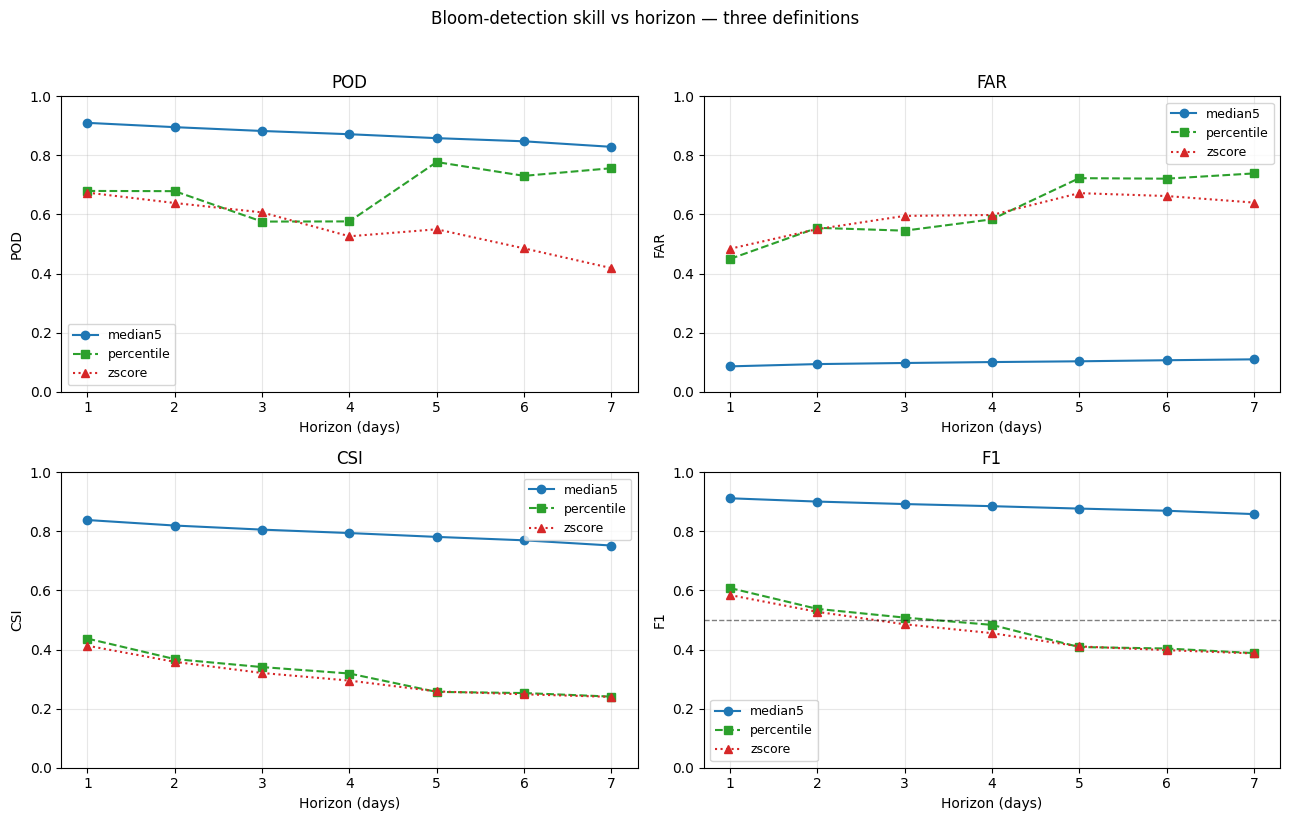

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metric_axes = dict(zip(["POD", "FAR", "CSI", "F1"], axes.flat))

styles = {
    "median5": (
        "o",
        "#1f77b4",
        "-",
    ),
    "percentile": (
        "s",
        "#2ca02c",
        "--",
    ),
    "zscore": (
        "^",
        "#d62728",
        ":",
    ),
}

for name, (marker, color, ls) in styles.items():
    sub = skill[skill.definition == name].sort_values("horizon")
    for metric, ax in metric_axes.items():
        ax.plot(sub.horizon, sub[metric], marker=marker, color=color, linestyle=ls, label=name)

for metric, ax in metric_axes.items():
    ax.set_xlabel("Horizon (days)")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=9)
    if metric == "F1":
        ax.axhline(0.5, color="k", linestyle="--", linewidth=1, alpha=0.5, label="F1=0.5 gate")

plt.suptitle("Bloom-detection skill vs horizon — three definitions", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_bloom_skill.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Validation Gate 9

The gate checks the 360,000-row v2 sample; strict 2021 fitting, 2022 cutoff calibration, and untouched 2023 testing; all 21 horizon-definition results; substantial eligible counts; saved figures and cutoffs; plausible auxiliary/rare event rates; rare-event F1 degradation from H+1 to H+7; and at least one rare H+3 definition with F1 ≥ 0.50 and FAR ≤ 0.60.

`median5` remains an auxiliary above-median regime diagnostic. The headline is chosen only between the percentile and z-score rare-event definitions.


In [6]:
results = {}

RARE_EVENT_DEFS = [
    "percentile",
    "zscore",
]

rates = (
    skill.groupby("definition")["bloom_rate"]
    .mean()
)

# Structural checks
results["360,000-row corrected sample used"] = (
    len(sample) == 360_000
)

results["test is exactly 2023"] = (
    set(test["time"].dt.year.unique()) == {2023}
)

results["calibration is exactly 2022"] = (
    set(validation["time"].dt.year.unique())
    == {2022}
)

results["calibration precedes test"] = (
    validation["time"].max()
    < test["time"].min()
)

results["21 skill rows recorded"] = (
    len(skill) == len(HORIZONS) * len(BLOOM_DEFS)
)

results["all score sample sizes are substantial"] = (
    int(skill["N"].min()) >= 50_000
)

results["bloom skill figure saved"] = (
    FIG_DIR / "09_bloom_skill.png"
).exists()

# Median+5 is an auxiliary regime threshold, not a rare-event
# definition. A rate around 50% is expected for this diagnostic.
median5_rate = float(rates["median5"])

results["median5 regime rate is plausible"] = (
    0.30 <= median5_rate <= 0.70
)

# The actual rare-event definitions should remain uncommon.
results["percentile bloom rate is plausible"] = (
    0.02 <= float(rates["percentile"]) <= 0.30
)

results["zscore bloom rate is plausible"] = (
    0.01 <= float(rates["zscore"]) <= 0.25
)

# Require meaningful degradation between H+1 and H+7 for both
# rare-event definitions.
rare_decay_ok = True

for definition in RARE_EVENT_DEFS:
    by_horizon = (
        skill[
            skill["definition"] == definition
        ]
        .set_index("horizon")
    )

    if not (
        float(by_horizon.loc[1, "F1"])
        >= float(by_horizon.loc[7, "F1"]) + 0.05
    ):
        rare_decay_ok = False

results["rare-event F1 degrades with horizon"] = (
    rare_decay_ok
)

# Select the strongest rare-event definition at H+3.
h3_rare = (
    skill[
        (skill["horizon"] == 3)
        & skill["definition"].isin(
            RARE_EVENT_DEFS
        )
    ]
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

headline_row = h3_rare.iloc[0]
HEADLINE_DEFINITION = str(
    headline_row["definition"]
)

results["at least one rare definition has H+3 F1 ≥ 0.50"] = (
    float(headline_row["F1"]) >= 0.50
)

# A detector with extreme false alarms is not operationally useful,
# even when F1 barely passes.
results["headline H+3 FAR ≤ 0.60"] = (
    float(headline_row["FAR"]) <= 0.60
)

# Confirm every calibration threshold was produced.
expected_calibration_pairs = {
    (h, definition)
    for h in HORIZONS
    for definition in BLOOM_DEFS
}

actual_calibration_pairs = set(
    zip(
        calibration_table["horizon"],
        calibration_table["definition"],
    )
)

results["all validation cutoffs recorded"] = (
    actual_calibration_pairs
    == expected_calibration_pairs
)

for name, passed in results.items():
    print(
        f"{'PASS' if passed else 'FAIL'}  {name}"
    )

print("\nMean observed event rate:")
for definition in BLOOM_DEFS:
    role = (
        "auxiliary regime"
        if definition == "median5"
        else "rare event"
    )

    print(
        f"  {definition:12s} "
        f"{rates[definition] * 100:5.1f}%  "
        f"({role})"
    )

print("\nRare-event H+3 results:")
print(
    h3_rare[
        [
            "definition",
            "POD",
            "FAR",
            "CSI",
            "F1",
            "N",
        ]
    ].round(3).to_string(index=False)
)

print(
    f"\nHeadline definition: "
    f"{HEADLINE_DEFINITION}"
)
print(
    f"Headline H+3 F1 : "
    f"{float(headline_row['F1']):.3f}"
)
print(
    f"Headline H+3 FAR: "
    f"{float(headline_row['FAR']):.3f}"
)

failed = [
    name
    for name, passed in results.items()
    if not passed
]

if failed:
    NEED_FALLBACK = not bool(
        results[
            "at least one rare definition has H+3 F1 ≥ 0.50"
        ]
    )

    raise RuntimeError(
        "Validation Gate 9 failed:\n- "
        + "\n- ".join(failed)
    )

NEED_FALLBACK = False

# Persist only after the corrected gate passes.
skill.to_csv(
    PROC_DIR / "bloom_skill.csv",
    index=False,
)

calibration_table.to_csv(
    PROC_DIR / "bloom_calibration.csv",
    index=False,
)

bloom_manifest = {
    "reference_period": {
        "start": "2021-01-01",
        "end": str(REFERENCE_END.date()),
    },
    "calibration_period": {
        "start": "2022-01-01",
        "end": "2022-12-31",
    },
    "test_period": {
        "start": "2023-01-01",
        "end": "2023-12-31",
    },
    "climatology": (
        "per-pixel calendar-month statistics; "
        "minimum 5 observations per pixel-month"
    ),
    "definitions": {
        "median5": (
            "forecast or truth exceeds 1.05 times "
            "the per-pixel annual median; auxiliary "
            "regime diagnostic, not treated as rare"
        ),
        "percentile": (
            "forecast or truth exceeds the per-pixel "
            "calendar-month P90"
        ),
        "zscore": (
            "calendar-month standardized anomaly "
            "exceeds 1.5 for truth; forecast cutoff "
            "calibrated on 2022"
        ),
    },
    "forecast_cutoff_calibration": (
        "cutoffs maximize F1 using only 2022 "
        "validation predictions from models fitted "
        "only on 2021"
    ),
    "headline_definition": HEADLINE_DEFINITION,
    "headline_h3": {
        key: (
            int(headline_row[key])
            if key == "N"
            else float(headline_row[key])
        )
        for key in [
            "POD",
            "FAR",
            "CSI",
            "F1",
            "N",
        ]
    },
    "cumulative_sum_status": (
        "deferred to full-grid annual inference; "
        "not valid on the sparse supervised sample"
    ),
    "calibrated_cutoffs": {
        str(h): {
            definition: float(
                calibration_cutoffs[h][definition]
            )
            for definition in BLOOM_DEFS
        }
        for h in HORIZONS
    },
}

(
    PROC_DIR / "bloom_detection_manifest.json"
).write_text(
    json.dumps(
        bloom_manifest,
        indent=2,
    )
)

print("\nGate 9 PASSED.")
print(
    f"Headline rare-event definition: "
    f"{HEADLINE_DEFINITION}"
)
print(
    "Important limitation: H+3 passes narrowly; "
    "the false-alarm ratio remains substantial."
)
print("Proceed to Notebook 10.")

PASS  360,000-row corrected sample used
PASS  test is exactly 2023
PASS  calibration is exactly 2022
PASS  calibration precedes test
PASS  21 skill rows recorded
PASS  all score sample sizes are substantial
PASS  bloom skill figure saved
PASS  median5 regime rate is plausible
PASS  percentile bloom rate is plausible
PASS  zscore bloom rate is plausible
PASS  rare-event F1 degrades with horizon
PASS  at least one rare definition has H+3 F1 ≥ 0.50
PASS  headline H+3 FAR ≤ 0.60
PASS  all validation cutoffs recorded

Mean observed event rate:
  median5       50.3%  (auxiliary regime)
  percentile    17.7%  (rare event)
  zscore        13.7%  (rare event)

Rare-event H+3 results:
definition   POD   FAR   CSI    F1     N
percentile 0.576 0.545 0.341 0.508 71687
    zscore 0.607 0.595 0.321 0.486 71687

Headline definition: percentile
Headline H+3 F1 : 0.508
Headline H+3 FAR: 0.545

Gate 9 PASSED.
Headline rare-event definition: percentile
Important limitation: H+3 passes narrowly; the false-

## 9.5 — Fallback status

The Isolation Forest branch is not triggered when at least one calibrated rare-event definition clears H+3 F1 = 0.50. A residual anomaly model would require a separate leakage-safe validation study and is not silently substituted here.

In [7]:
if NEED_FALLBACK:
    print(
        "No rare-event definition cleared the H+3 "
        "F1 gate. A separate anomaly-detection study "
        "would be required."
    )
else:
    print(
        "Isolation Forest fallback not triggered. "
        f"The calibrated {HEADLINE_DEFINITION} "
        "definition is the headline detector."
    )

Isolation Forest fallback not triggered. The calibrated percentile definition is the headline detector.


---
## Result

The calibrated percentile definition is the headline rare-event detector. Its H+3 skill passes narrowly, so the false-alarm ratio is reported alongside F1. The median+5 diagnostic is retained only as an above-median regime classification.